# Cafeína, atención y sueño en semana de exámenes
**Proyecto 2 · MA-0321 Cálculo Diferencial e Integral · UCR Sede del Sur (Golfito) · II-2026**
Kendall Fabricio Villalobos Villalta · Código C-09

**Cliente:** Coordinación de Vida Estudiantil, Sede del Sur, que prepara una campaña sobre el
consumo de café y bebidas energéticas en semana de exámenes.

**Pregunta de decisión.** ¿Cuántas tomas, de qué bebida y hasta qué hora conviene consumir cafeína
para tener más horas de atención entre las 8:00 y las 20:00 sin afectar el sueño?

**Criterio de éxito.** Para cada tipo de persona (eliminación rápida, normal y lenta) se recomienda el
plan con más horas de concentración eficaz, con concentración al acostarse menor que el umbral y
consumo diario dentro del máximo.

> Datos simulados con fines didácticos; los resultados no constituyen una recomendación médica.

Este cuaderno usa las funciones de `src/` (las mismas que la aplicación web) y se ejecuta de
principio a fin con `jupyter nbconvert --execute analisis.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import escenarios as esc
from src import graficos as gr
from src import limpieza, modelo
from src.config import RUTA_DATOS

%matplotlib inline
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.precision", 3)

## 1. Lectura y validación de la base
Se lee el Excel con `pd.read_excel(ruta, sheet_name=None)`; `leer_base` verifica hojas y columnas y
`leer_parametros` verifica que cada parámetro tenga la unidad esperada. Ningún valor del problema
se escribe en el código.

In [2]:
hojas = limpieza.leer_base(RUTA_DATOS)
param = limpieza.leer_parametros(hojas["Parametros"])
print({h: d.shape for h, d in hojas.items()})
param

{'Concentraciones': (780, 3), 'Voluntarios': (60, 7), 'Pruebas_atencion': (480, 3), 'Bebidas': (6, 3), 'Planes': (13, 3), 'Parametros': (8, 3), 'Diccionario': (22, 4)}


Parametros(dosis_mg=200.0, ka=3.0, c_efecto=1.5, c_sueno=1.0, hora_dormir=23.0, max_diario_mg=400.0, inicio=8.0, fin=20.0)

In [3]:
hojas["Parametros"]

,parametro,valor,unidad
0,Dosis de la prueba,200.0,mg
1,Constante de absorción típica,3.0,1/h
2,Umbral de efecto en la atención,1.5,mg/L
3,Umbral para no afectar el sueño,1.0,mg/L
4,Hora de acostarse,23.0,hora
5,Máximo diario recomendado,400.0,mg
6,Inicio de la jornada de estudio,8.0,hora
7,Fin de la jornada de estudio,20.0,hora


## 2. Exploración
### 2.1 Calidad: registros, faltantes y rangos

In [4]:
limpieza.resumen_calidad(hojas)

,hoja,columna,registros,faltantes,minimo,maximo
0,Concentraciones,tiempo_h,780,0,0.250,24.00
1,Concentraciones,concentracion_mg_L,780,6,0.003,13.57
2,Voluntarios,edad,60,0,18.000,26.00
3,Voluntarios,peso_kg,60,0,45.000,96.70
4,Voluntarios,tazas_cafe_habituales_dia,60,0,0.000,4.00
5,Pruebas_atencion,tiempo_h,480,0,0.000,12.00
6,Pruebas_atencion,tiempo_reaccion_ms,480,0,128.000,400.00


### 2.2 Patrones en el tiempo
Concentración media y tiempo de reacción medio en cada momento de muestreo. La concentración sube
hasta un pico cerca de 1 h y luego decae; el tiempo de reacción hace lo contrario.

In [5]:
conc = hojas["Concentraciones"]
pruebas = hojas["Pruebas_atencion"]
patron_c = conc.groupby("tiempo_h")["concentracion_mg_L"].agg(["mean", "std", "count"])
patron_rt = pruebas.groupby("tiempo_h")["tiempo_reaccion_ms"].agg(["mean", "std"])
patron_c.join(patron_rt, lsuffix="_C_mg_L", rsuffix="_RT_ms", how="outer")

/var/folders/s0/3cmzds1n77b4354p35zjzjr00000gn/T/ipykernel_2229/3550285461.py:5: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  patron_c.join(patron_rt, lsuffix="_C_mg_L", rsuffix="_RT_ms", how="outer")


,mean_C_mg_L,std_C_mg_L,count,mean_RT_ms,std_RT_ms
tiempo_h,,,,,
0.00,NaN,NaN,NaN,335.833,28.833
0.25,2.561,0.728,59.0,NaN,NaN
0.50,3.767,1.082,59.0,239.550,31.471
0.75,4.210,1.214,60.0,NaN,NaN
1.00,4.419,1.652,60.0,230.833,30.193
1.50,4.131,1.128,60.0,NaN,NaN
2.00,3.940,1.110,60.0,238.767,38.565
3.00,3.446,0.940,59.0,NaN,NaN
4.00,3.055,0.920,59.0,257.600,32.327


### 2.3 Características de los voluntarios

In [6]:
vol = hojas["Voluntarios"]
display(vol.describe())
display(vol[["sexo", "fuma", "anticonceptivo_hormonal"]].apply(pd.Series.value_counts))

,edad,peso_kg,tazas_cafe_habituales_dia
count,60.000,60.000,60.000
mean,22.017,70.188,2.267
std,2.665,12.316,1.376
min,18.000,45.000,0.000
25%,19.000,62.100,1.000
50%,22.000,70.700,2.000
75%,24.000,77.550,3.000
max,26.000,96.700,4.000


,sexo,fuma,anticonceptivo_hormonal
Hombre,28.0,NaN,NaN
Mujer,32.0,NaN,NaN
No,NaN,49.0,51.0
Sí,NaN,11.0,9.0


## 3. Faltantes y atípicos
**Criterio (ver `docs/bitacora_supuestos.md`):**
* Atípico: punto interior que difiere más de ×1,8 del valor esperado por interpolación log-lineal
  entre sus vecinos válidos (se marcan uno a uno, el peor primero).
* Faltantes interiores y atípicos: interpolación lineal en el tiempo (equivale a lo que hace el
  trapecio, no inventa área).
* Faltantes en 24 h: extrapolación con la recta de ln C de la fase terminal.
* Los valores imputados no se usan para estimar k.

In [7]:
conc_limpio, bitacora = limpieza.limpiar_concentraciones(conc)
print("Registros:", len(conc), "->", len(conc_limpio), "| faltantes tras limpiar:",
      conc_limpio["concentracion_mg_L"].isna().sum())
bitacora

Registros: 780 -> 780 | faltantes tras limpiar: 0


,voluntario,tiempo_h,estado,valor_original,valor_final,tratamiento
0,V04,4.00,atípico,3.60,1.373,interpolación lineal en el tiempo
1,V17,1.00,atípico,13.57,4.049,interpolación lineal en el tiempo
2,V21,10.00,atípico,2.39,0.816,interpolación lineal en el tiempo
3,V31,0.50,faltante,NaN,4.637,interpolación lineal en el tiempo
4,V31,24.00,faltante,NaN,0.078,extrapolación exponencial (fase terminal)
5,V32,3.00,faltante,NaN,1.800,interpolación lineal en el tiempo
6,V44,0.25,faltante,NaN,2.924,interpolación lineal en el tiempo
7,V45,4.00,faltante,NaN,1.598,interpolación lineal en el tiempo
8,V48,24.00,faltante,NaN,0.506,extrapolación exponencial (fase terminal)


## 4. Modelo: AUC, vida media, depuración y volumen
Para cada voluntario:

* $k$ = −pendiente de $\ln C$ contra $t$ para $t \ge 6$ h (decrecimiento exponencial
  $C = C_0 e^{-kt}$ ⇒ $\ln C = \ln C_0 - kt$); $t_{1/2} = \ln 2 / k$.
* $AUC = \int_0^{24} C\,dt$ (trapecio, con $C(0)=0$) $+ \int_{24}^{\infty} C(24)e^{-k(t-24)}dt$,
  y la integral impropia vale exactamente $C(24)/k$.
* $CL = D/AUC$ (L/h) y $V = CL/k$ (L).

In [8]:
resultados = modelo.analizar_todos(conc_limpio, param.dosis_mg)
resultados.describe().T

,count,mean,std,min,25%,50%,75%,max
k_1_h,60.0,0.145,0.055,0.040,0.107,0.135,0.176,0.312
vida_media_h,60.0,5.552,2.593,2.222,3.949,5.148,6.469,17.369
r2_terminal,60.0,0.995,0.009,0.940,0.996,0.998,0.999,1.000
auc_0_24_trapecio,60.0,37.540,15.356,12.553,26.964,36.624,44.020,93.099
auc_0_24_simpson,60.0,35.511,14.979,11.794,25.183,34.123,41.778,91.232
cola_mg_h_l,60.0,3.810,8.872,0.008,0.475,1.521,3.740,61.178
auc_total,60.0,41.350,22.554,12.585,27.884,38.453,46.970,154.277
pct_cola,60.0,5.845,7.059,0.063,1.412,3.986,7.580,39.655
cl_l_h,60.0,6.050,3.022,1.296,4.258,5.201,7.181,15.892
v_l,60.0,41.171,9.413,18.071,33.923,42.793,46.616,63.339


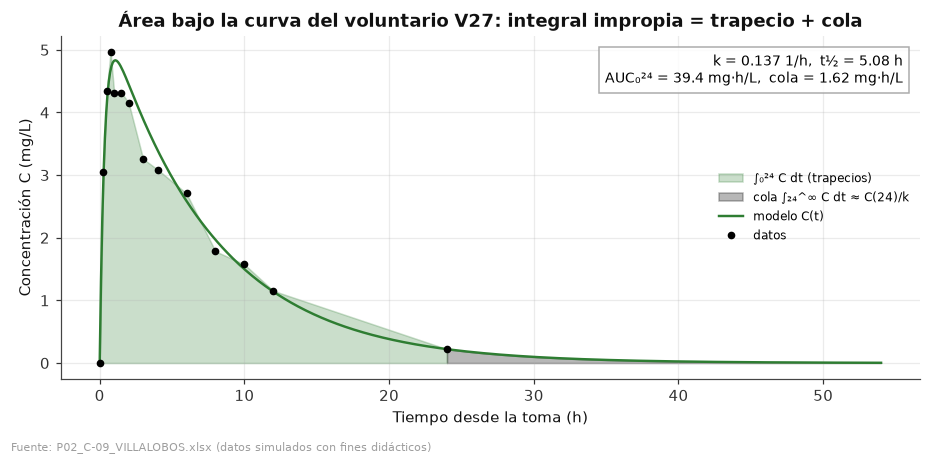

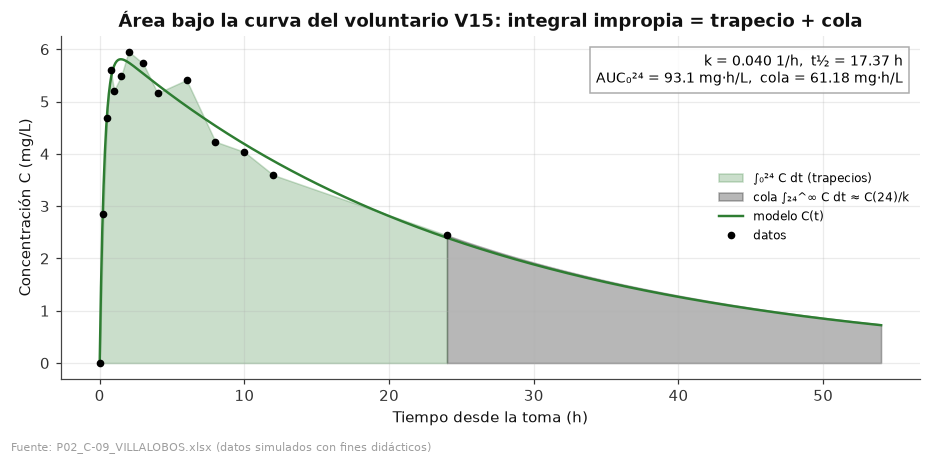

In [9]:
vidas = resultados["vida_media_h"]
tipico = (vidas - vidas.median()).abs().idxmin()
fig = gr.fig_voluntario_desde_tablas(conc_limpio, resultados, tipico, param.ka, param.dosis_mg)
fig = gr.fig_voluntario_desde_tablas(conc_limpio, resultados, vidas.idxmax(), param.ka, param.dosis_mg)

**Interpretación.** El AUC (mg·h/L) es la exposición total a la cafeína. La cola impropia aporta en
mediana el 4 % del AUC, pero en personas de eliminación lenta llega al 40 %: truncar en 24 h
subestimaría mucho su exposición. V/peso ≈ 0,58 L/kg y CL/peso ≈ 0,085 L/(h·kg), órdenes de magnitud
coherentes con la literatura farmacocinética de la cafeína.

In [10]:
print("Cola (% del AUC): mediana", round(resultados["pct_cola"].median(), 2),
      "| máx.", round(resultados["pct_cola"].max(), 2))
print("V/peso (L/kg):", round((resultados["v_l"] / vol.set_index("voluntario")["peso_kg"]).median(), 3))

Cola (% del AUC): mediana 3.99 | máx. 39.65
V/peso (L/kg): 0.574


## 5. Verificación y validación
1. **Validación obligatoria:** integrando numéricamente (Simpson propio) el modelo $C(t)$ de cada
   voluntario hasta 200 h se recupera $D/(Vk)$ con error < 0,5 %.
2. $\int_0^\infty e^{-kt}dt = 1/k$ con la integral truncada.
3. **Contra los acumulados de la base:** el acumulado observado $\int_0^{24}C\,dt$ (trapecio) contra
   la integral exacta del modelo en [0, 24] (antiderivada analítica).
4. Trapecio contra Simpson (dos reglas para la misma integral).

In [11]:
validacion = modelo.validar_auc_modelo(resultados, param.ka, param.dosis_mg)
print(f"Error relativo máximo D/(Vk): {100 * validacion['error_rel'].max():.4f} %")
for k in [resultados["k_1_h"].min(), resultados["k_1_h"].median(), resultados["k_1_h"].max()]:
    aprox = modelo.integral_exponencial_truncada(k, 200)
    print(f"k = {k:.3f}: truncada = {aprox:.4f} h, 1/k = {1 / k:.4f} h, error = {abs(aprox * k - 1):.2e}")

Error relativo máximo D/(Vk): 0.0346 %
k = 0.040: truncada = 25.0490 h, 1/k = 25.0576 h, error = 3.42e-04
k = 0.135: truncada = 7.4259 h, 1/k = 7.4259 h, error = 9.41e-12
k = 0.312: truncada = 3.2060 h, 1/k = 3.2060 h, error = 3.29e-10


,count,mean,std,min,25%,50%,75%,max
auc_obs_0_24,60.0,37.540,15.356,1.255e+01,2.696e+01,36.624,44.020,93.099
auc_modelo_0_24,60.0,37.487,15.381,1.255e+01,2.693e+01,36.617,43.831,94.277
error_rel_acumulado,60.0,0.002,0.003,1.717e-06,4.177e-04,0.001,0.003,0.013
error_rel_simpson_modelo,60.0,0.057,0.027,2.833e-03,3.713e-02,0.065,0.078,0.100
rmse_mg_L,60.0,0.233,0.080,9.163e-02,1.780e-01,0.219,0.278,0.457
r2,60.0,0.964,0.021,8.898e-01,9.583e-01,0.969,0.977,0.994


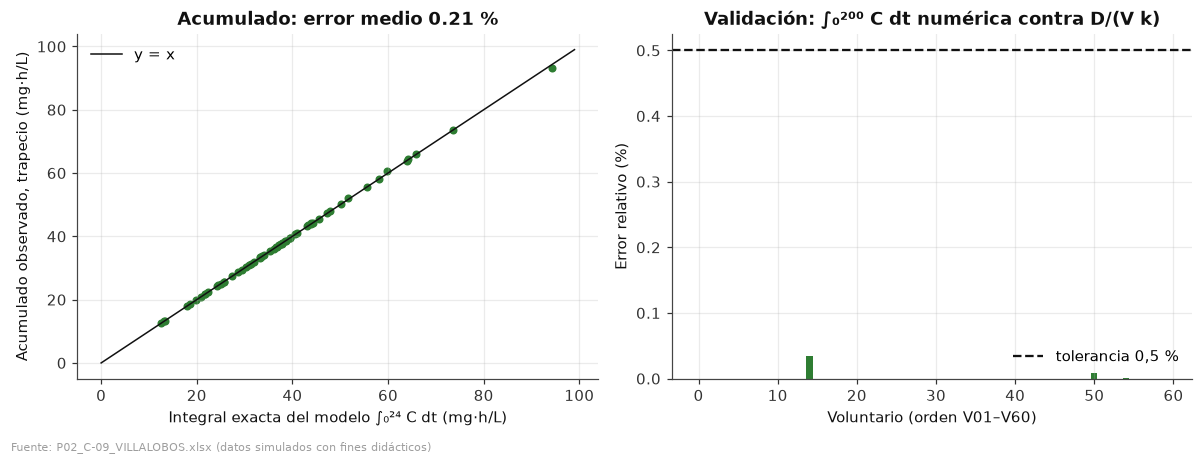

In [12]:
verif = modelo.verificar_contra_datos(conc_limpio, resultados, param.ka, param.dosis_mg)
display(verif.describe().T)
fig = gr.fig_verificacion(validacion, verif)

**Lectura.** El acumulado observado y la integral exacta del modelo difieren 0,2 % en promedio y el
modelo explica 96 % de la variación de cada perfil (R² medio). Simpson difiere 5,7 % de la integral
exacta: la parábola que pasa por 10, 12 y 24 h no sigue a la exponencial en el último tramo, por lo
que para estos datos el trapecio es la regla adecuada.

## 6. Velocidad de eliminación: factores y grupos

,factor,categoria,n,mediana_t12_h,media_t12_h,p_valor
0,fuma,Sí,11,3.131,3.469,2.000e-04
1,fuma,No,49,5.499,6.020,2.000e-04
2,anticonceptivo_hormonal,Sí,9,7.197,9.299,3.999e-04
3,anticonceptivo_hormonal,No,51,4.814,4.891,3.999e-04


vida_media_h                 k_1_h                   v_l                
             median    min     max median    min    max  median     min     max
grupo                                                                          
rápida        3.611  2.222   4.375  0.192  0.158  0.312  42.872  18.071  63.339
normal        5.148  4.529   5.810  0.135  0.119  0.153  41.266  24.334  61.935
lenta         6.878  6.021  17.369  0.101  0.040  0.115  42.854  25.470  51.169

fuma                     No    Sí   
anticonceptivo_hormonal  No Sí No Sí
grupo                               
rápida                   11  0  9  0
normal                   18  1  1  0
lenta                    12  7  0  1

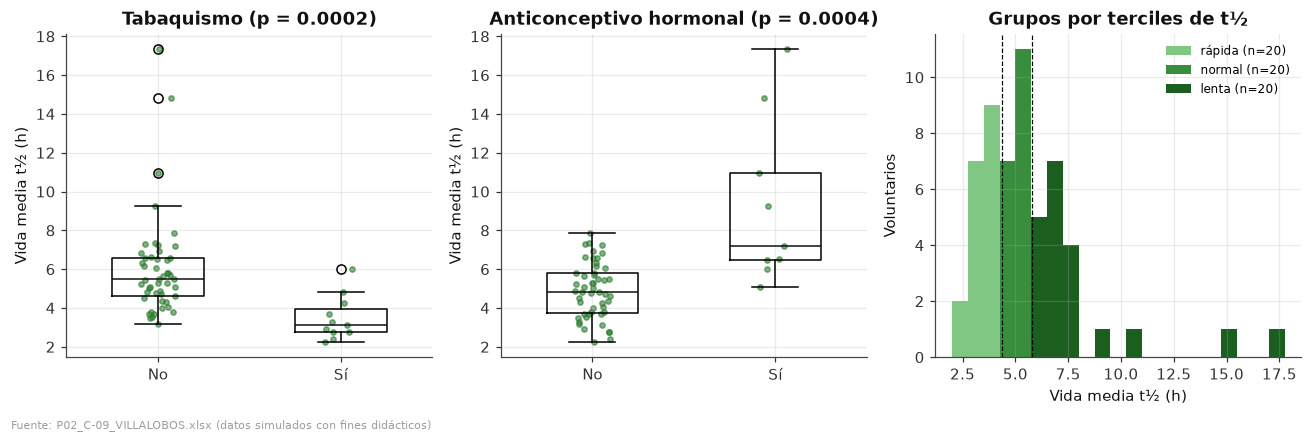

In [13]:
clasificados = esc.clasificar(resultados, vol)
factores = esc.comparar_factores(clasificados)
display(factores)
display(clasificados.groupby("grupo", observed=True)[["vida_media_h", "k_1_h", "v_l"]].agg(["median", "min", "max"]))
display(pd.crosstab(clasificados["grupo"], [clasificados["fuma"], clasificados["anticonceptivo_hormonal"]]))
fig = gr.fig_vida_media(clasificados, factores)

Fumar acorta la vida media (mediana 3,1 h contra 5,5 h) y el anticonceptivo hormonal la alarga
(7,2 h contra 4,8 h); ambas diferencias son significativas en una prueba de permutaciones
(p < 0,001). Por eso los fumadores se concentran en el grupo rápido y las usuarias de anticonceptivo
en el lento.

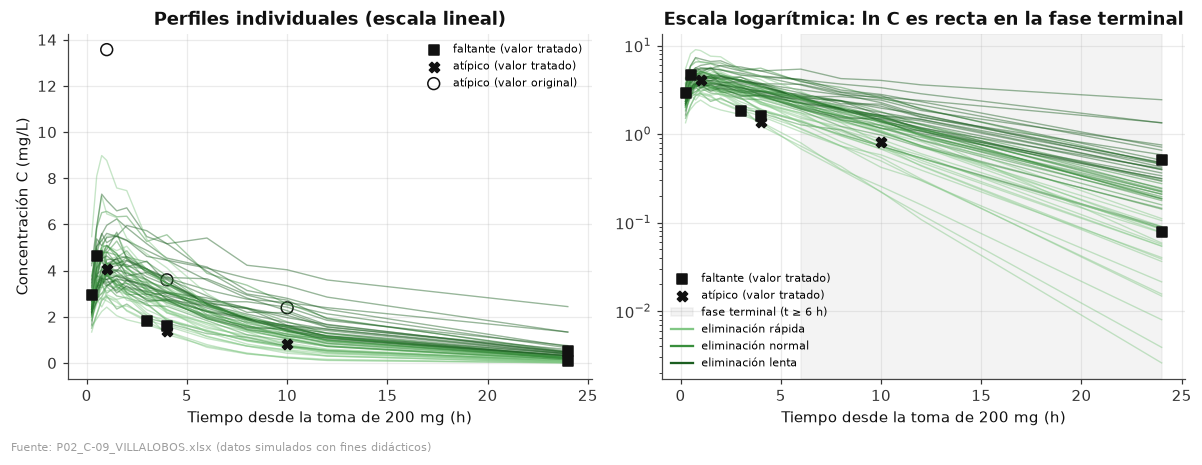

In [14]:
fig = gr.fig_perfiles(conc_limpio, clasificados)

## 7. Atención y concentración

RelacionAtencion(pendiente=23.937030118861024, intercepto=3.924031226065118, r2=0.7745592143225934, basal_ms=335.8333333333333)


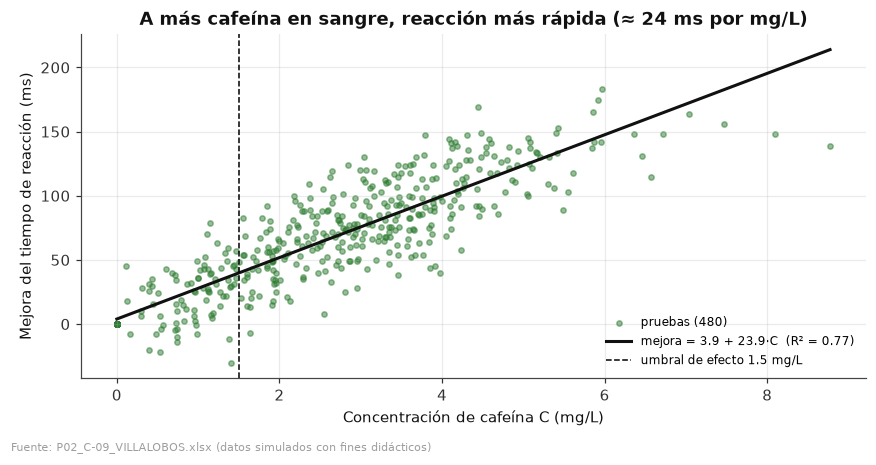

In [15]:
atencion = limpieza.unir_atencion(limpieza.revisar_pruebas(pruebas), conc_limpio)
relacion = modelo.ajustar_atencion(atencion)
print(relacion)
fig = gr.fig_atencion(atencion, relacion, param.c_efecto)

Cada mg/L de cafeína mejora el tiempo de reacción en ≈ 24 ms (R² = 0,77). En el umbral de efecto
(1,5 mg/L) la mejora esperada es ≈ 40 ms, ≈ 12 % del tiempo basal (336 ms).

## 8. Planes de consumo: superposición y horas con efecto
$C_{plan}(t) = \sum_j C(t-t_j; D_j)$ y $H_{ef} = \int_8^{20} \mathbf 1[C_{plan}(t)\ge c_{ef}]\,dt$.
La integral de la indicadora se calcula con la fracción exacta de cada subintervalo de una malla de
1 min y se compara con los cruces hallados por bisección.

In [16]:
planes = esc.construir_planes(hojas["Planes"], hojas["Bebidas"])
modelos = esc.modelos_por_grupo(clasificados, param.ka)
individuos = esc.modelos_individuales(clasificados, param.ka)
for codigo, plan in planes.items():
    print(codigo, plan.descripcion(), f"({plan.total_mg:.0f} mg)")
modelos

A 08:00 Café chorreado (95 mg)
B 08:00 Café chorreado + 13:00 Café chorreado (190 mg)
C 08:00 Café chorreado + 16:00 Café chorreado (190 mg)
D 08:00 Café chorreado + 12:00 Café chorreado + 16:00 Café chorreado (285 mg)
E 08:00 Café chorreado + 14:00 Energética grande (255 mg)
F 10:00 Espresso + 14:00 Espresso + 18:00 Espresso (189 mg)


{'rápida': ModeloUnCompartimento(k=0.19201624221219366, ka=3.0, v_l=42.87245331572542),
 'normal': ModeloUnCompartimento(k=0.1346641211358066, ka=3.0, v_l=41.26596847729629),
 'lenta': ModeloUnCompartimento(k=0.1007784534972492, ka=3.0, v_l=42.853536693158034)}

,grupo,plan,descripcion,n_tomas,horas_efecto,c_dormir,c_media_jornada,mejora_rt_ms,cafeina_mg,pct_personas_duermen_bien,cumple_sueno,cumple_maximo,cumple
0,rápida,A,08:00 Café chorreado,1,1.957,0.133,0.859,20.564,95.0,100.0,True,True,True
1,rápida,B,08:00 Café chorreado + 13:00 Café chorreado,2,5.913,0.480,1.553,37.170,190.0,100.0,True,True,True
2,rápida,C,08:00 Café chorreado + 16:00 Café chorreado,2,5.139,0.750,1.344,32.174,190.0,75.0,True,True,True
3,rápida,D,08:00 Café chorreado + 12:00 Café chorreado + ...,3,9.887,1.037,2.085,49.900,285.0,40.0,False,True,False
4,rápida,E,08:00 Café chorreado + 14:00 Energética grande,2,7.867,0.841,1.932,46.245,255.0,60.0,True,True,True
5,rápida,F,10:00 Espresso + 14:00 Espresso + 18:00 Espresso,3,3.808,1.009,1.134,27.146,189.0,45.0,False,True,False
6,normal,A,08:00 Café chorreado,1,3.151,0.320,1.128,27.007,95.0,100.0,True,True,True
7,normal,B,08:00 Café chorreado + 13:00 Café chorreado,2,9.690,0.947,1.972,47.197,190.0,55.0,True,True,True
8,normal,C,08:00 Café chorreado + 16:00 Café chorreado,2,7.031,1.259,1.682,40.273,190.0,15.0,False,True,False
9,normal,D,08:00 Café chorreado + 12:00 Café chorreado + ...,3,11.137,1.807,2.599,62.216,285.0,0.0,False,True,False


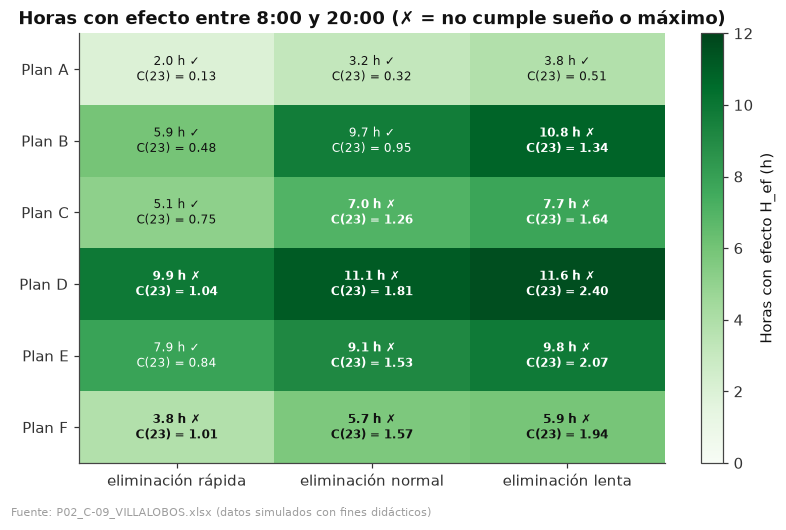

In [17]:
evaluacion = esc.evaluar_planes(planes, modelos, param, relacion, 0, individuos)
display(evaluacion)
fig = gr.fig_mapa_planes(evaluacion)

In [18]:
metodos = esc.comparar_metodos_horas(planes, modelos, param)
print(f"Error relativo máximo entre métodos: {metodos['error_rel'].max():.2e}")
metodos.head(6)

Error relativo máximo entre métodos: 5.19e-05


,grupo,plan,h_malla,h_biseccion,error_rel
0,rápida,A,1.957,1.957,4.916e-05
1,rápida,B,5.913,5.913,3.540e-05
2,rápida,C,5.139,5.140,4.047e-05
3,rápida,D,9.887,9.888,1.720e-05
4,rápida,E,7.867,7.867,2.542e-05
5,rápida,F,3.808,3.808,5.189e-05


## 9. Recomendación, escenarios y sensibilidad

,grupo,vida_media_h,plan,descripcion,horas_efecto,c_dormir,cafeina_mg,hora_limite_ultima_toma,maximo_diario_mg,mejora_rt_ms,pct_personas_duermen_bien
0,rápida,3.610,E,08:00 Café chorreado + 14:00 Energética grande,7.867,0.841,255.0,15.055,303.195,46.245,60.0
1,normal,5.147,B,08:00 Café chorreado + 13:00 Café chorreado,9.690,0.947,190.0,13.606,200.694,47.197,55.0
2,lenta,6.878,A,08:00 Café chorreado,3.822,0.506,95.0,14.762,187.784,30.330,85.0


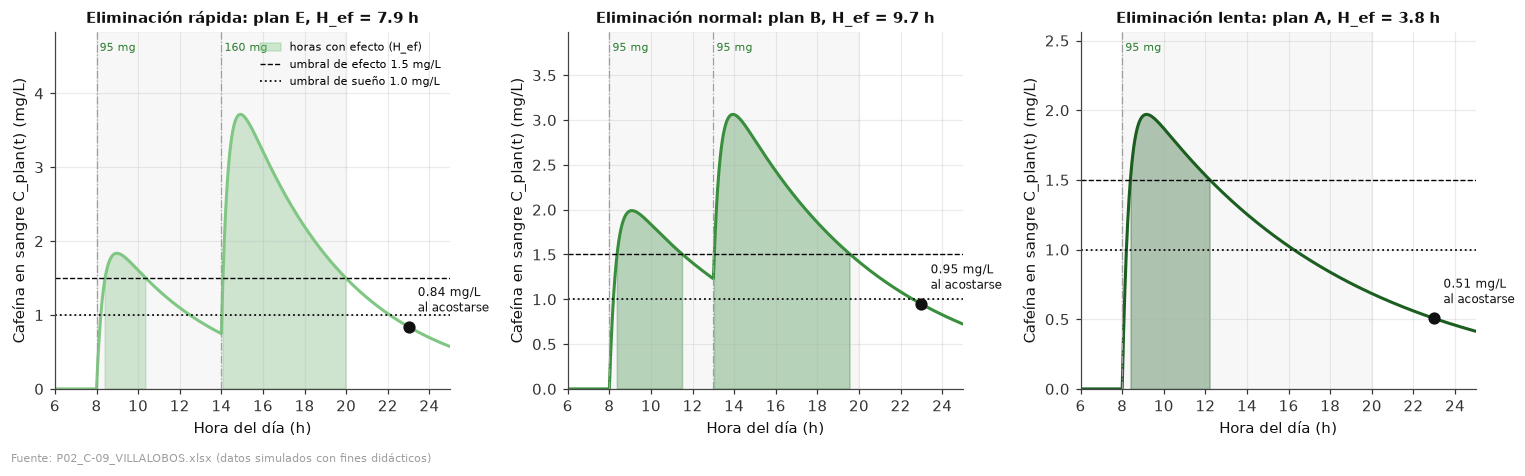

In [19]:
recomendacion = esc.recomendar(evaluacion)
guia = esc.guia_consumo(recomendacion, planes, modelos, param)
display(guia)
fig = gr.fig_planes_recomendados(guia, planes, modelos, param)

,escenario,grupo,plan,horas_efecto,c_dormir,pct_personas_duermen_bien
37,Acostarse 1 h antes,rápida,B,5.913,0.581,90.0
42,Acostarse 1 h antes,normal,A,3.151,0.366,100.0
48,Acostarse 1 h antes,lenta,A,3.822,0.560,85.0
4,Base (día 1),rápida,E,7.867,0.841,60.0
7,Base (día 1),normal,B,9.690,0.947,55.0
12,Base (día 1),lenta,A,3.822,0.506,85.0
22,Semana de exámenes (5 días),rápida,E,8.287,0.850,60.0
25,Semana de exámenes (5 días),normal,B,10.980,0.986,40.0
30,Semana de exámenes (5 días),lenta,A,4.844,0.555,85.0


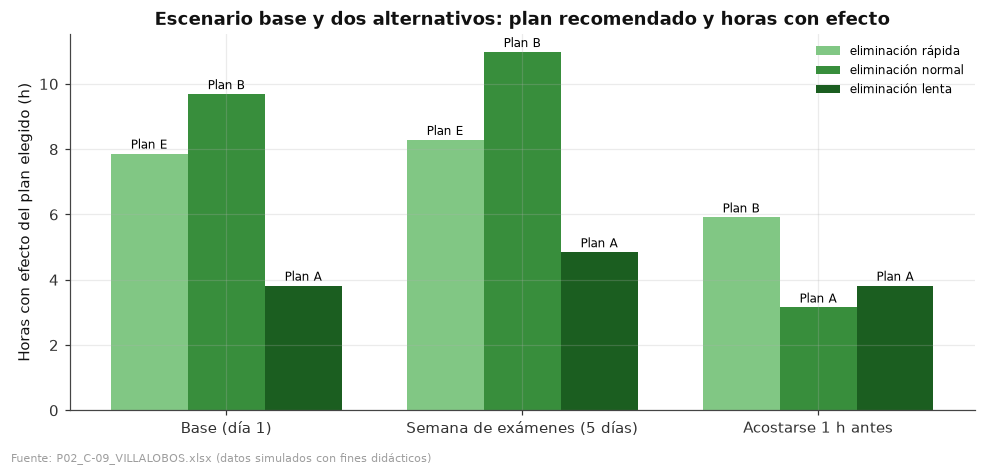

In [20]:
lista = esc.escenarios_definidos(param)
ev_esc = esc.evaluar_escenarios(lista, planes, modelos, relacion, individuos)
rec_esc = esc.recomendar(ev_esc)
display(rec_esc[["escenario", "grupo", "plan", "horas_efecto", "c_dormir", "pct_personas_duermen_bien"]])
fig = gr.fig_escenarios(ev_esc, rec_esc)

parametro
V (volumen)         3
hora de dormir      3
k (eliminación)     3
ka (absorción)      0
umbral de efecto    0
umbral de sueño     3
Name: decisiones que cambian, dtype: int64

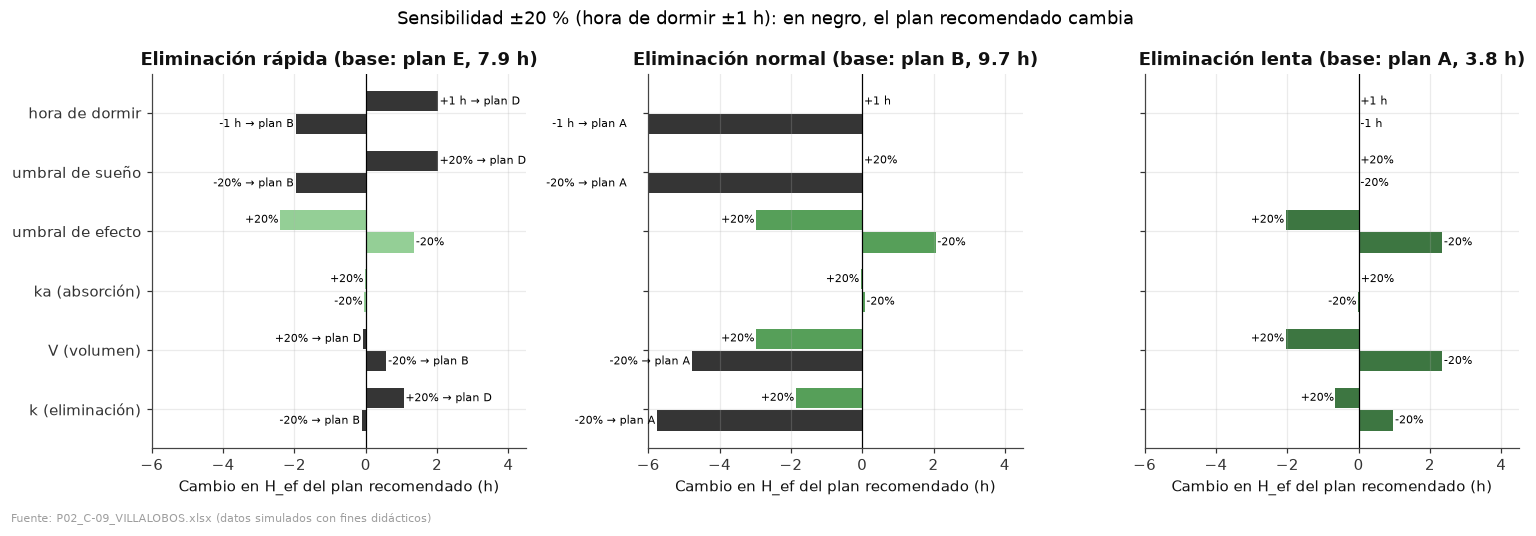

In [21]:
sens = esc.sensibilidad(planes, modelos, param)
display(sens.groupby("parametro")["cambia_decision"].sum().rename("decisiones que cambian"))
fig = gr.fig_sensibilidad(sens, guia)

,bebida,cafeina_mg,rápida,normal,lenta
0,Espresso,63,20.658,19.517,18.837
1,Café chorreado,95,18.512,16.467,14.762
2,Bebida energética,80,19.407,17.743,16.467
3,Energética grande,160,15.797,12.596,9.589
4,Té negro,45,22.021,21.917,21.830
5,Gaseosa de cola,35,22.021,21.917,21.830


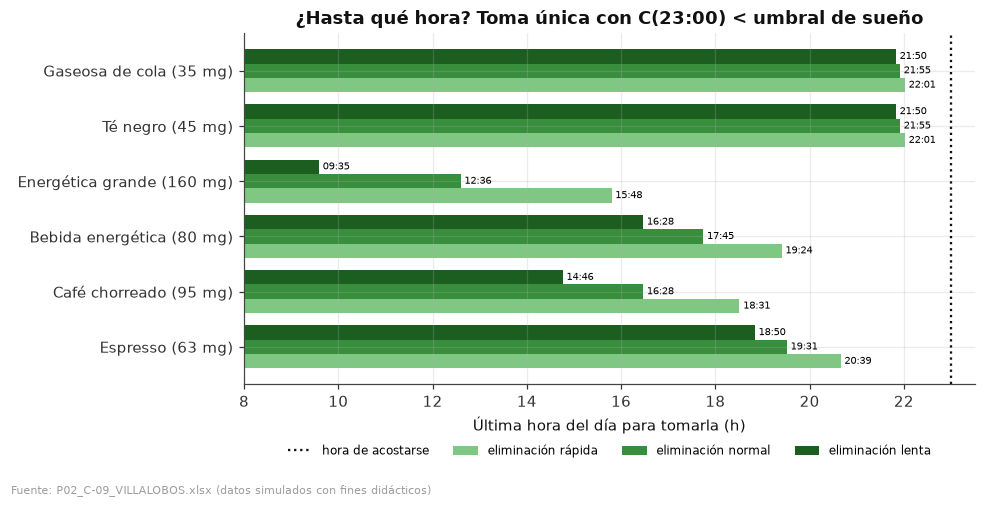

In [22]:
limites = esc.tabla_horas_limite(modelos, hojas["Bebidas"], param)
display(limites)
fig = gr.fig_horas_limite(limites, param)

### 9.1 Criterio prudente y plan ajustado
La persona típica del grupo puede cumplir el umbral de sueño mientras una parte importante del grupo
no lo cumple. El criterio prudente exige que al menos el 80 % del grupo quede bajo el umbral. El
plan ajustado busca entre todas las combinaciones de 1 a 3 bebidas de la base a horas enteras.

,grupo,plan,descripcion,horas_efecto,c_dormir,pct_personas_duermen_bien
0,rápida,B,08:00 Café chorreado + 13:00 Café chorreado,5.913,0.480,100.0
1,normal,A,08:00 Café chorreado,3.151,0.320,100.0
2,lenta,A,08:00 Café chorreado,3.822,0.506,85.0


,grupo,descripcion,n_tomas,horas_efecto,c_dormir,pct_personas_duermen_bien,cafeina_mg
0,rápida,08:00 Energética grande + 13:00 Gaseosa de col...,3,10.774,0.689,80.0,258.0
1,normal,08:00 Energética grande + 14:00 Té negro,2,10.857,0.878,80.0,205.0
2,lenta,08:00 Bebida energética + 09:00 Té negro,2,6.709,0.691,80.0,125.0


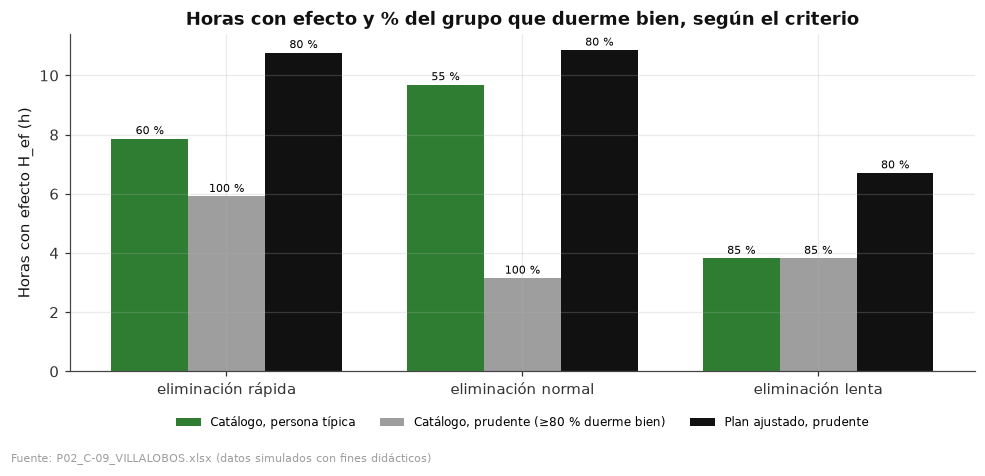

In [23]:
prudente = esc.guia_consumo(esc.recomendar(evaluacion, 80.0), planes, modelos, param)
ajustados = esc.planes_optimizados(modelos, individuos, hojas["Bebidas"], param, 80.0)
display(prudente[["grupo", "plan", "descripcion", "horas_efecto", "c_dormir", "pct_personas_duermen_bien"]])
display(ajustados)
fig = gr.fig_comparacion_criterios(guia, prudente, ajustados)

## 10. Conclusión
* **Criterio oficial (catálogo, persona típica):** eliminación rápida → plan E (café 8:00 +
  energética grande 14:00, 7,9 h); normal → plan B (cafés a las 8:00 y 13:00, 9,7 h); lenta →
  plan A (un café a las 8:00, 3,8 h).
* Con el criterio prudente (≥ 80 % del grupo duerme bien), el patrón ganador es **una dosis grande
  temprano y dosis pequeñas después**: el plan ajustado da 10,8 h (rápida), 10,9 h (normal) y
  6,7 h (lenta).
* El parámetro que más mueve la decisión es la velocidad de eliminación (k) junto con el umbral de
  sueño y la hora de acostarse; ka y el umbral de efecto no cambian ninguna decisión.
* Limitaciones: datos simulados, una sola dosis de prueba, cinética lineal supuesta, sin tolerancia.